# Predictive maintenance: inspect, train, and visualize



In [1]:
from pathlib import Path
import sys
import pandas as pd
import plotly.express as px
from src.data_pipeline import dataset_path, load_cycles

PROJECT_DIR = Path.cwd()
DATASET = 'FD001'  # Change to FD002, FD003, or FD004
train = load_cycles(dataset_path(PROJECT_DIR, f'train_{DATASET}.txt'))
print(f'{DATASET}: {train.engine_id.nunique()} engines, {len(train):,} cycles')
train.head()

FD001: 100 engines, 20,631 cycles


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


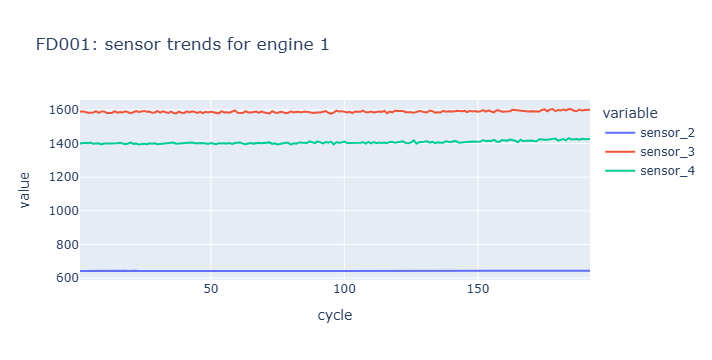

In [2]:
engine = train.loc[train.engine_id == 1]
px.line(engine, x='cycle', y=['sensor_2', 'sensor_3', 'sensor_4'],
        title=f'{DATASET}: sensor trends for engine 1')

## Train, validate, and score the official test trajectories

The validation split holds out complete engines. The official test report uses the provided final RUL labels.

In [3]:
import subprocess

subprocess.run([sys.executable, 'train_xgboost.py', '--dataset', DATASET], check=True)
subprocess.run([sys.executable, 'precompute_predictions.py', '--dataset', DATASET], check=True)

CompletedProcess(args=['C:\\Users\\Admin\\anaconda3\\python.exe', 'precompute_predictions.py', '--dataset', 'FD001'], returncode=0)

,value
dataset,FD001
validation,20% held-out engines; all cycles; capped RUL l...
validation_engines,20
mae,11.60585
rmse,16.295579
r2,0.847405
nasa_score,29573.959555


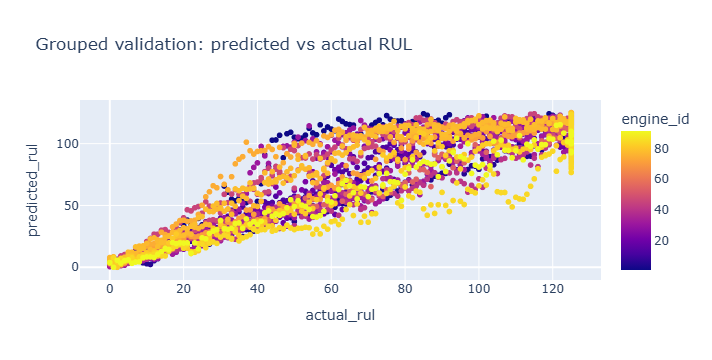

In [5]:
metrics = pd.read_json(PROJECT_DIR / 'reports' / f'{DATASET.lower()}_metrics.json', typ='series')
validation = pd.read_csv(PROJECT_DIR / 'reports' / f'{DATASET.lower()}_validation_predictions.csv')
display(metrics.to_frame('value'))
px.scatter(validation, x='actual_rul', y='predicted_rul', color='engine_id',
            title='Grouped validation: predicted vs actual RUL')

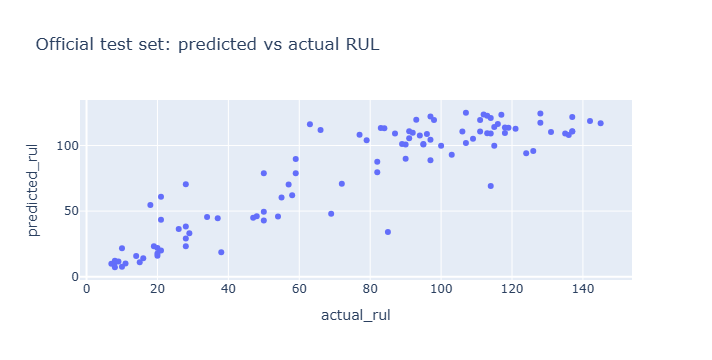

In [7]:
fleet = pd.read_csv(PROJECT_DIR / 'Data' / 'predictions' / 'fleet_predictions.csv')
px.scatter(fleet, x='actual_rul', y='predicted_rul', hover_name='engine_id',
            title='Official test set: predicted vs actual RUL')